# 18. Norms of Vectors, Functions and Matrices
Run the cells in order. Keep `lafp.py` in the same folder.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from lafp import *
%matplotlib inline

Unit balls of $\lVert\cdot\rVert_p$ in $\R^2$. For $p\ge1$ they are convex and grow with $p$: from the diamond ($p=1$) through the disc ($p=2$) to the square ($p=\infty$). For $p<1$ (dashed) they are star-shaped but not convex, and as $p\to0$ they shrink onto the two axes, the "ball" of the count of nonzeros.

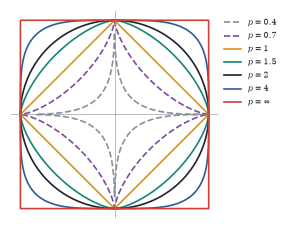

In [2]:
t = np.linspace(0, 2 * np.pi, 2000); c, s = np.cos(t), np.sin(t)
fig, ax = plt.subplots(figsize=(W * 0.55, W * 0.55))
for p, col, ls in [(0.4, GRAY, "--"), (0.7, PLUM, "--"), (1, GOLD, "-"), (1.5, TEAL, "-"), (2, INK, "-"), (4, BLUE, "-"), (np.inf, RED, "-")]:
    nr = np.maximum(abs(c), abs(s)) if p == np.inf else (abs(c) ** p + abs(s) ** p) ** (1 / p)
    ax.plot(c / nr, s / nr, color=col, ls=ls, lw=1.1, label=(r"$p=\infty$" if p == np.inf else f"$p={p}$"))
ax.set_aspect("equal"); ax.axhline(0, color=GRAY, lw=0.4); ax.axvline(0, color=GRAY, lw=0.4); ax.axis("off")
ax.legend(fontsize=5.5, loc="upper right", bbox_to_anchor=(1.32, 1.0))

Minimum-norm solutions of one equation $a_1v_1+a_2v_2=b$ (the line). Growing $\ell^2$ discs (left) first touch the line at a point with both coordinates nonzero. Growing $\ell^1$ diamonds (right) first touch it at a vertex on an axis: the $\ell^1$ minimizer is sparse.

findfont: Failed to find font weight semibold for DejaVu Serif, now using 700.


findfont: Failed to find font weight semibold for DejaVu Serif, now using 700.


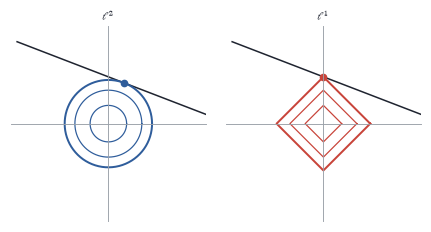

In [3]:
a = np.array([1.0, 2.6]); b = 2.0
x2 = a * b / (a @ a); r2 = np.linalg.norm(x2)
k = np.argmax(np.abs(a)); x1 = np.zeros(2); x1[k] = b / a[k]; r1 = np.abs(x1).sum()
t = np.linspace(0, 2 * np.pi, 400)
fig, axs = plt.subplots(1, 2, figsize=(W * 0.85, 2.0))
xx = np.linspace(-1.5, 2.5, 2)
for ax, ttl in [(axs[0], r"$\ell^2$"), (axs[1], r"$\ell^1$")]:
    plane(ax, 1.6, grid=False); ax.plot(xx, (b - a[0] * xx) / a[1], color=INK, lw=1); ax.set_title(ttl, fontsize=7)
for rr in [0.3, 0.55, r2]:
    axs[0].plot(rr * np.cos(t), rr * np.sin(t), color=BLUE, lw=0.8 if rr != r2 else 1.3)
for rr in [0.3, 0.55, r1]:
    axs[1].plot(rr * np.array([1, 0, -1, 0, 1]), rr * np.array([0, 1, 0, -1, 0]), color=RED, lw=0.8 if rr != r1 else 1.3)
axs[0].plot(*x2, "o", color=BLUE, ms=4); axs[1].plot(*x1, "o", color=RED, ms=4)

The operator norm as the largest stretch. Each panel shows the unit ball of a vector norm (grey) and its image under $A=\begin{bmatrix}1&2\\0&1\end{bmatrix}$ (blue), with the smallest ball of the same norm containing the image (red, dashed); its radius is $\lVert A\rVert$. For $\ell^1$ it is the largest column sum $3$, for $\ell^2$ the top singular value $1+\sqrt2$, for $\ell^\infty$ the largest row sum $3$.

findfont: Failed to find font weight semibold for DejaVu Serif, now using 700.


findfont: Failed to find font weight semibold for DejaVu Serif, now using 700.


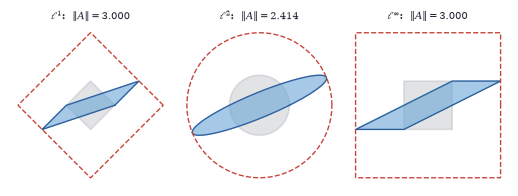

In [4]:
A = np.array([[1, 2], [0, 1.]]); t = np.linspace(0, 2 * np.pi, 800); c, s = np.cos(t), np.sin(t)
fig, axs = plt.subplots(1, 3, figsize=(W, 1.8))
for ax, p, nrm in [(axs[0], 1, 3.0), (axs[1], 2, 1 + np.sqrt(2)), (axs[2], np.inf, 3.0)]:
    den = np.maximum(abs(c), abs(s)) if p == np.inf else (abs(c) ** p + abs(s) ** p) ** (1 / p)
    B = np.vstack([c / den, s / den])
    ax.fill(*B, color=GRAY, alpha=0.25); ax.fill(*(A @ B), color=SKY, alpha=0.6); ax.plot(*(A @ B), color=BLUE, lw=0.8)
    ax.plot(*(nrm * B), color=RED, ls="--", lw=0.9); ax.set_aspect("equal"); ax.axis("off")
    ax.set_title((r"$\ell^\infty$" if p == np.inf else rf"$\ell^{p}$") + f":  $\\|A\\|={nrm:.3f}$", fontsize=6.5)

Gelfand's formula and transient growth. For a $10\times10$ upper bidiagonal matrix with $0.9$ on the diagonal and $0.5$ above it, $\rho(A)=0.9$, but $\lVert A^k\rVert_2$ (blue) grows by several orders of magnitude before the asymptotic decay $\rho^k$ (dashed) takes over. The quantity $\lVert A^k\rVert^{1/k}$ (red, right) converges slowly to $\rho=0.9$.

Text(0.5, 1.0, '$\\|A^k\\|^{1/k}\\to\\rho(A)$')

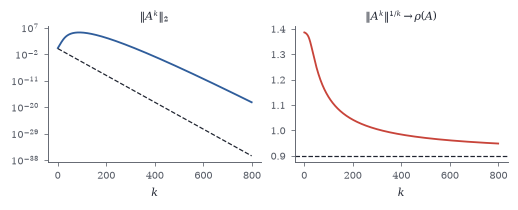

In [5]:
n = 10; A = 0.9 * np.eye(n) + 0.5 * np.eye(n, k=1)
ks = np.arange(1, 800); norms = []; P = np.eye(n)
for k in ks:
    P = P @ A; norms.append(np.linalg.norm(P, 2))
norms = np.array(norms)
fig, axs = plt.subplots(1, 2, figsize=(W, 1.8))
axs[0].semilogy(ks, norms, color=BLUE); axs[0].semilogy(ks, 0.9 ** ks, "--", color=INK, lw=0.8); axs[0].set_xlabel("$k$"); axs[0].set_title(r"$\|A^k\|_2$", fontsize=7)
axs[1].plot(ks, norms ** (1 / ks), color=RED); axs[1].axhline(0.9, color=INK, ls="--", lw=0.8); axs[1].set_xlabel("$k$"); axs[1].set_title(r"$\|A^k\|^{1/k}\to\rho(A)$", fontsize=7)

Left: two nearly parallel lines (an ill-conditioned $2\times2$ system). Shifting one line by a small amount $\delta b$ (dashed) moves the intersection a long way. Right: condition numbers of Hilbert matrices $H_n$ (blue) grow like $e^{3.5n}$, while those of random Gaussian matrices (gold) grow only linearly in $n$; the red line marks $1/\varepsilon$ for double precision, beyond which no digit of the solution can be trusted.

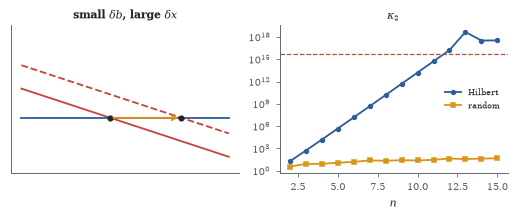

In [6]:
from scipy.linalg import hilbert
fig, axs = plt.subplots(1, 2, figsize=(W, 1.9))
ax = axs[0]; xx = np.linspace(-0.5, 3, 2)
ax.plot(xx, 1 - 0.0 * xx, color=BLUE); ax.plot(xx, (1 - 0.05 * xx) / 0.95, color=RED); ax.plot(xx, (1.06 - 0.05 * xx) / 0.95, color=RED, ls="--")
A2 = np.array([[0, 1], [0.05, 0.95]]); p1 = np.linalg.solve(A2, [1, 1]); p2 = np.linalg.solve(A2, [1, 1.06])
ax.plot(*p1, "o", color=INK, ms=3); ax.plot(*p2, "o", color=INK, ms=3); ax.set_ylim(0.85, 1.25); ax.set_xticks([]); ax.set_yticks([])
ax.annotate("", xy=p2, xytext=p1, arrowprops=dict(arrowstyle="->", color=GOLD, lw=1.2)); ax.set_title("small $\\delta b$, large $\\delta x$", fontsize=7)
ns = np.arange(2, 16); rng = np.random.default_rng(0)
axs[1].semilogy(ns, [np.linalg.cond(hilbert(n)) for n in ns], "o-", color=BLUE, ms=2.5, label="Hilbert")
axs[1].semilogy(ns, [np.median([np.linalg.cond(rng.normal(size=(n, n))) for _ in range(50)]) for n in ns], "s-", color=GOLD, ms=2.5, label="random")
axs[1].axhline(1 / np.finfo(float).eps, color=RED, ls="--", lw=0.8); axs[1].set_xlabel("$n$"); axs[1].set_title(r"$\kappa_2$", fontsize=7); axs[1].legend(fontsize=5.5)

In [7]:
rng = np.random.default_rng(0); n = 6
A = rng.normal(size=(n, n)); A += np.diag(np.abs(A).sum(1) + 1)          # strictly diagonally dominant
b = rng.normal(size=n); D = np.diag(np.diag(A)); x = np.zeros(n)
for k in range(40): x = np.linalg.solve(D, (D - A) @ x + b)
print("rho(D^-1(L+U)) =", round(max(abs(np.linalg.eigvals(np.linalg.solve(D, D - A)))), 4), "  Jacobi error after 40 steps:", np.linalg.norm(x - np.linalg.solve(A, b)))

rho(D^-1(L+U)) = 0.4071   Jacobi error after 40 steps: 1.4304896245381993e-16
